# M2 · Notebook 02 — Pembersihan dan Validasi Data
**Exploratory Data Analysis (KMTI21133)** · Dataset: *Sleep Debt and Screen Time: Late Night Phone Habits* (Kaggle, CC BY-SA 4.0)

Notebook ini mengerjakan rencana dari `01_quality.ipynb`. Prinsipnya:

1. `data/raw/` **hanya dibaca**. Seluruh perubahan ditulis sebagai kode, hasilnya disimpan ke `data/processed/`.
2. **Setiap keputusan dicatat saat dikerjakan** lewat `catat(...)`: apa masalahnya, apa keputusannya, mengapa, alternatif apa yang dipertimbangkan, dan bukti dampaknya. Log itu diekspor otomatis menjadi `cleaning_log.md` di akhir.
3. Setiap langkah diikuti **validasi sebelum–sesudah**.
4. Data pribadi ditangani **dan diverifikasi** sebelum disimpan.

| Langkah | Isi |
|---|---|
| 1 | Buang spasi di tepi teks |
| 2 | Buang duplikat persis |
| 3 | Ubah angka yang tersimpan sebagai teks |
| 4 | Seragamkan kategori |
| 5 | Nilai di luar domain → NaN |
| 6 | Keputusan nilai kosong (dengan eksperimen alternatif) |
| 7 | Penanganan data pribadi (hash, generalisasi, cek k-anonymity) |
| 8 | Validasi akhir sebelum–sesudah |
| 9 | Simpan hasil dan ekspor `cleaning_log.md` |

> **Cara menjalankan:** *Restart & Run All* dari folder `notebooks/`. Opsional: set variabel lingkungan `SALT_EDA` (garam rahasia tim) sebelum menjalankan.

## Persiapan

In [1]:
import os, hashlib, hmac, warnings, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 80)

ROOT = Path('..') if (Path('..') / 'data' / 'raw').exists() else Path('.')
RAW  = ROOT / 'data' / 'raw' / 'bedtime_screentime_sleep_debt_kotor.csv'
PROC = ROOT / 'data' / 'processed'
FIG  = ROOT / 'reports' / 'figures'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

mentah = pd.read_csv(RAW)       # tidak pernah diubah; semua kerja pada salinan `df`
N_MENTAH = len(mentah)
print('Data mentah:', mentah.shape)

# Bukti data/raw sama dengan yang didiagnosis di 01_quality
SHA_RAW = hashlib.sha256(RAW.read_bytes()).hexdigest()
ref = ROOT / 'reports' / 'raw_sha256.txt'
if ref.exists():
    assert SHA_RAW == ref.read_text().strip(), 'data/raw berbeda dari saat diagnosis!'
    print('SHA-256 cocok dengan catatan 01_quality: data/raw tidak berubah.')
else:
    print('Peringatan: reports/raw_sha256.txt tidak ada; jalankan 01_quality dulu.')

Data mentah: (8600, 18)
SHA-256 cocok dengan catatan 01_quality: data/raw tidak berubah.


In [2]:
# Jejak keputusan: DICATAT SAAT dikerjakan, bukan direkonstruksi belakangan.
jejak = []

def catat(langkah, kolom, terdampak, masalah, keputusan, alasan, alternatif, bukti, oleh):
    jejak.append({'langkah': langkah, 'kolom': kolom, 'baris_terdampak': int(terdampak),
                  'masalah': masalah, 'keputusan': keputusan, 'alasan': alasan,
                  'alternatif': alternatif, 'bukti': bukti, 'oleh': oleh})
    print(f'[{langkah}] {kolom}: {int(terdampak)} baris terdampak')

KOLOM_NUM = ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'caffeine_post_5pm_mg',
             'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours',
             'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score']

def ke_angka(s):
    return pd.to_numeric(s.astype('string').str.extract(r'(-?\d+(?:\.\d+)?)')[0], errors='coerce')

df = mentah.copy()

## Langkah 1 — Buang spasi di tepi teks
**Masalah (dari 01_quality):** spasi tersembunyi memecah `groupby` dan melambungkan `nunique` (mis. `Night Owl ` dan `Night Owl` dihitung berbeda), serta membuat `user_id` yang sama tampak berbeda.

**Keputusan:** `strip()` pada **semua** kolom teks. Dilakukan **sebelum** deduplikasi agar duplikat ber-spasi tidak lolos.

**Alternatif:** hanya strip kolom kunci. Ditolak karena spasi di kolom kategori sama merusaknya.

In [3]:
kolom_teks = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
sebelum_unik = {c: df[c].nunique() for c in kolom_teks}

n_sel = 0
baris_kena = pd.Series(False, index=df.index)
for c in kolom_teks:
    s = df[c].astype('string')
    kena = s.notna() & (s != s.str.strip())
    n_sel += int(kena.sum())
    baris_kena |= kena
    df[c] = s.str.strip()

print('Sel yang berspasi di tepi:', n_sel, '| baris terdampak:', int(baris_kena.sum()))
bukti = pd.DataFrame({'unik_sebelum': pd.Series(sebelum_unik),
                      'unik_sesudah': {c: df[c].nunique() for c in kolom_teks}})
bukti['selisih'] = bukti['unik_sebelum'] - bukti['unik_sesudah']
display(bukti[bukti['selisih'] > 0])

catat('L1 Strip spasi', 'semua kolom teks', baris_kena.sum(),
      'Spasi di awal/akhir teks memecah kategori dan ID yang sama',
      'strip() pada seluruh kolom teks, sebelum deduplikasi',
      'Spasi tidak membawa informasi; efeknya hanya memecah grup',
      'Strip hanya kolom kunci (ditolak: kolom kategori sama rawannya)',
      f'{n_sel} sel dirapikan; unik berkurang pada ' + ', '.join(bukti.index[bukti["selisih"] > 0]),
      'kode')

Sel yang berspasi di tepi: 500 | baris terdampak: 488


,unik_sebelum,unik_sesudah,selisih
gender,14,12,2
occupation_type,25,15,10
chronotype,11,8,3
primary_bedtime_app,24,18,6


[L1 Strip spasi] semua kolom teks: 488 baris terdampak


## Langkah 2 — Buang duplikat persis
**Masalah:** 100 baris duplikat persis (diagnosis Bagian 4). Duplikat menggandakan bobot responden yang sama dan menaikkan *n* secara palsu.

**Keputusan:** simpan baris pertama, buang salinan berikutnya, **setelah memverifikasi** bahwa setiap pasangan benar-benar identik di seluruh kolom (sehingga pilihan `keep='first'` vs `'last'` tidak berpengaruh).

**Alternatif:** deduplikasi hanya berdasar `user_id` (ditolak: bisa membuang baris yang isinya berbeda; tetapi diperiksa dulu bahwa hal itu tidak terjadi).

In [4]:
dup_mask = df.duplicated(keep=False)
pasangan = df[dup_mask]
# Apakah ada user_id yang sama tetapi isi BERBEDA? (kalau ada, memilih keep mempengaruhi hasil)
beda_isi = int((pasangan.groupby('user_id').nunique(dropna=False) > 1).any(axis=1).sum())
print('Baris terlibat duplikat   :', int(dup_mask.sum()))
print('Pasangan dengan isi beda  :', beda_isi, '  (harus 0)')
assert beda_isi == 0

n_sebelum = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_dibuang = n_sebelum - len(df)

assert df['user_id'].is_unique
nomor = df['user_id'].str.extract(r'(\d+)')[0].astype(int)
assert nomor.min() == 1 and nomor.max() == len(df) == nomor.nunique()   # ID 1..8500 tanpa celah

print(f'Sebelum: {n_sebelum} baris | sesudah: {len(df)} | dibuang: {n_dibuang}')
print('user_id unik dan berurutan lengkap: USR-%05d s.d. USR-%05d' % (nomor.min(), nomor.max()))

catat('L2 Duplikat', 'seluruh kolom', n_dibuang,
      'Baris duplikat persis menggandakan responden yang sama',
      'drop_duplicates(keep="first")',
      'Semua pasangan identik di seluruh kolom, sehingga tidak ada informasi hilang',
      'Dedup berdasar user_id saja (ditolak; dicek: tidak ada user_id sama dengan isi berbeda)',
      f'{n_sebelum} -> {len(df)} baris; user_id unik; ID berurutan 1..{len(df)} tanpa celah',
      'kode')

Baris terlibat duplikat   : 200
Pasangan dengan isi beda  : 0   (harus 0)
Sebelum: 8600 baris | sesudah: 8500 | dibuang: 100
user_id unik dan berurutan lengkap: USR-00001 s.d. USR-08500
[L2 Duplikat] seluruh kolom: 100 baris terdampak


## Langkah 3 — Ubah angka yang tersimpan sebagai teks
**Masalah:** `age` (`"45 tahun"`), `bedtime_phone_minutes` (`"41 min"`), `rem_sleep_pct` (`"-"`) bertipe teks, sehingga `mean()` gagal.

**Keputusan:** ambil angkanya dengan regex dan ubah ke `float`. Placeholder `"-"` menjadi `NaN`. Tipe dikonversi **setelah** pengecekan bahwa tidak ada digit yang hilang.

**Alternatif:** `pd.to_numeric(errors='coerce')` langsung. Ditolak karena `"45 tahun"` akan menjadi `NaN` dan angka 45 hilang diam-diam.

In [5]:
for k in ['age', 'bedtime_phone_minutes', 'rem_sleep_pct']:
    asli = df[k].astype('string')
    murni = pd.to_numeric(asli, errors='coerce').notna()
    bersatuan = asli.notna() & ~murni & asli.str.contains(r'\d')
    placeholder = asli.notna() & ~murni & ~asli.str.contains(r'\d')
    baru = ke_angka(asli)

    # Pengaman 1: setiap teks yang mengandung digit harus menghasilkan angka
    assert baru[asli.notna() & asli.str.contains(r'\d')].notna().all()
    # Pengaman 2: placeholder tanpa digit menjadi NaN
    assert baru[placeholder].isna().all()

    df[k] = baru.astype(float)
    catat('L3 Tipe teks -> angka', k, bersatuan.sum() + placeholder.sum(),
          f'Kolom bertipe teks: {int(bersatuan.sum())} nilai bersatuan, {int(placeholder.sum())} placeholder',
          'Regex ambil angka, ubah ke float; placeholder tanpa digit menjadi NaN',
          'Satuan hanya penjelas; angkanya valid',
          'to_numeric(errors="coerce") langsung (ditolak: membuang angka pada teks bersatuan)',
          f'dtype: teks -> {df[k].dtype}; {int(bersatuan.sum())} nilai bersatuan diselamatkan',
          'kode')
    print(f'{k:24s} bersatuan={int(bersatuan.sum()):3d}  placeholder={int(placeholder.sum()):3d}  dtype={df[k].dtype}')

print()
print(df[['age', 'bedtime_phone_minutes', 'rem_sleep_pct']].describe().round(2).T)

[L3 Tipe teks -> angka] age: 30 baris terdampak
age                      bersatuan= 30  placeholder=  0  dtype=float64
[L3 Tipe teks -> angka] bedtime_phone_minutes: 50 baris terdampak
bedtime_phone_minutes    bersatuan= 50  placeholder=  0  dtype=float64
[L3 Tipe teks -> angka] rem_sleep_pct: 24 baris terdampak
rem_sleep_pct            bersatuan=  0  placeholder= 24  dtype=float64

                        count   mean    std  min   25%   50%   75%    max
age                    8500.0  34.55  18.82 -5.0  25.0  32.0  42.0  999.0
bedtime_phone_minutes  8500.0  59.25  36.93  1.0  31.0  51.0  79.0  180.0
rem_sleep_pct          8440.0  19.10   2.55  9.6  17.4  19.1  20.8   27.0


## Langkah 4 — Seragamkan kategori
**Masalah:** variasi huruf, spasi, pemisah `_`, singkatan, salah ketik, dan delapan bentuk untuk variabel biner.

**Keputusan:** dua tahap. (1) **Kode** menyeragamkan huruf, spasi, dan pemisah ke bentuk kunci. (2) **Keputusan manusia**, dicatat eksplisit di peta manual: `F`→`Female`, `M`→`Male`, empat salah ketik pada `sleep_debt_category`, dan pemetaan biner ke 1/0. Setiap peta dilindungi `assert` agar tidak ada nilai yang lolos tanpa dipetakan.

**Alternatif:** fuzzy matching otomatis. Ditolak karena tidak transparan dan bisa memetakan salah; dengan hanya empat kategori baku, peta manual lebih aman dan dapat diaudit.

In [6]:
def kunci(s):
    return (s.astype('string').str.strip().str.lower().str.replace(r'[\s_\-]+', ' ', regex=True))

LABEL_BAKU = {
    'gender'             : ['Female', 'Male', 'Non-Binary'],
    'occupation_type'    : ['Corporate 9-to-5', 'Student', 'Remote Tech', 'Freelance / Creative', 'Healthcare / Shift Worker'],
    'chronotype'         : ['Intermediate', 'Night Owl', 'Morning Lark'],
    'primary_bedtime_app': ['News / Reading', 'Streaming (Netflix/Hulu)', 'Messaging / Chat',
                            'YouTube', 'Instagram / Reddit', 'TikTok / Reels'],
    'sleep_debt_category': ['Optimal Recovery', 'Mild Deficit', 'Moderate Debt', 'Severe Sleep Debt'],
}

# KEPUTUSAN MANUSIA (kunci dalam bentuk ternormalisasi). Setiap entri = satu keputusan yang bisa diaudit.
PETA_MANUAL = {
    'gender': {'f': 'Female', 'm': 'Male'},
    'sleep_debt_category': {'sever sleep debt': 'Severe Sleep Debt', 'moderat debt': 'Moderate Debt',
                            'mild defisit': 'Mild Deficit', 'optimal recovry': 'Optimal Recovery'},
}

hasil_kat = []
for k, valid in LABEL_BAKU.items():
    sebelum = df[k].nunique()
    kk = kunci(df[k])
    peta = {kunci(pd.Series([v]))[0]: v for v in valid}      # otomatis
    peta.update(PETA_MANUAL.get(k, {}))                       # manual
    baru = kk.map(peta)

    tak_terpetakan = set(kk[kk.notna() & baru.isna()].unique())
    assert not tak_terpetakan, f'{k}: belum terpetakan -> {tak_terpetakan}'

    n_manual = int(kk.isin(PETA_MANUAL.get(k, {}).keys()).sum())
    df[k] = baru.astype('string')
    hasil_kat.append({'kolom': k, 'unik_sebelum': sebelum, 'unik_sesudah': df[k].nunique(),
                      'baris_via_keputusan_manual': n_manual})

# Biner
PETA_BINER = {'1': 1, 'yes': 1, 'true': 1, '0': 0, 'no': 0, 'false': 0}
kb = kunci(df['blue_light_filter_active'])
bb = kb.map(PETA_BINER)
assert not set(kb[kb.notna() & bb.isna()].unique()), 'nilai biner belum terpetakan'
sebelum_b = df['blue_light_filter_active'].nunique()
df['blue_light_filter_active'] = bb.astype('Int64')
hasil_kat.append({'kolom': 'blue_light_filter_active', 'unik_sebelum': sebelum_b,
                  'unik_sesudah': df['blue_light_filter_active'].nunique(), 'baris_via_keputusan_manual': 0})

tabel_kat = pd.DataFrame(hasil_kat)
display(tabel_kat)

for k in list(LABEL_BAKU) + ['blue_light_filter_active']:
    print(f'\n{k}:', df[k].value_counts(dropna=False).to_dict())

,kolom,unik_sebelum,unik_sesudah,baris_via_keputusan_manual
0,gender,12,3,134
1,occupation_type,15,5,0
2,chronotype,8,3,0
3,primary_bedtime_app,18,6,0
4,sleep_debt_category,8,4,40
5,blue_light_filter_active,8,2,0



gender: {'Female': 4347, 'Male': 3905, 'Non-Binary': 248}

occupation_type: {'Corporate 9-to-5': 2781, 'Remote Tech': 2104, 'Student': 1584, 'Healthcare / Shift Worker': 982, 'Freelance / Creative': 879, <NA>: 170}

chronotype: {'Intermediate': 3828, 'Night Owl': 2410, 'Morning Lark': 2135, <NA>: 127}

primary_bedtime_app: {'TikTok / Reels': 2198, 'YouTube': 1928, 'Instagram / Reddit': 1630, 'Streaming (Netflix/Hulu)': 1301, 'Messaging / Chat': 847, 'News / Reading': 596}

sleep_debt_category: {'Moderate Debt': 4462, 'Mild Deficit': 2004, 'Optimal Recovery': 1387, 'Severe Sleep Debt': 647}

blue_light_filter_active: {np.int64(0): 4524, np.int64(1): 3976}


In [7]:
catat('L4 Kategori', 'gender', tabel_kat.loc[0, 'baris_via_keputusan_manual'],
      f"Singkatan F/M dan variasi huruf/spasi ({tabel_kat.loc[0, 'unik_sebelum']} bentuk untuk 3 kategori)",
      'Normalisasi oleh kode; F -> Female dan M -> Male lewat peta manual',
      'Satu-satunya tafsiran wajar singkatan tersebut; tidak ada kolom yang bertentangan',
      f"Fuzzy matching (ditolak: tidak transparan); membuang baris F/M (ditolak: kehilangan {tabel_kat.loc[0, 'baris_via_keputusan_manual']} responden)",
      f"unik {tabel_kat.loc[0, 'unik_sebelum']} -> {tabel_kat.loc[0, 'unik_sesudah']}; distribusi akhir hanya Female/Male/Non-Binary", 'kode + manual')
catat('L4 Kategori', 'sleep_debt_category', tabel_kat.loc[4, 'baris_via_keputusan_manual'],
      'Empat salah ketik: Sever, Moderat, Defisit, Recovry',
      'Peta manual eksplisit ke 4 label baku, dilindungi assert',
      'Padanan benar tak ambigu karena hanya ada empat kategori baku',
      'Fuzzy matching (ditolak); mengubah salah ketik menjadi NaN (ditolak: label hilang padahal jelas maksudnya)',
      f"unik {tabel_kat.loc[4, 'unik_sebelum']} -> {tabel_kat.loc[4, 'unik_sesudah']}; assert tidak ada nilai di luar 4 kategori", 'kode + manual')
catat('L4 Kategori', 'occupation_type, chronotype, primary_bedtime_app', 0,
      'Variasi huruf, spasi, dan pemisah "_"',
      'Normalisasi kunci (strip, lowercase, pemisah seragam) lalu petakan ke label baku',
      'Perbedaan murni penulisan, bukan perbedaan makna',
      'Membiarkan apa adanya (ditolak: groupby memecah 3 kelompok chronotype menjadi 11)',
      'unik: ' + ', '.join(f"{tabel_kat.loc[i, 'kolom']} {tabel_kat.loc[i, 'unik_sebelum']} -> {tabel_kat.loc[i, 'unik_sesudah']}" for i in (1, 2, 3)), 'kode')
catat('L4 Kategori', 'blue_light_filter_active', 0,
      'Delapan representasi (1/0, Yes/No, True/False) untuk satu variabel biner',
      'Petakan ke 1/0 (Int64 agar NaN tetap boleh)',
      'Semua bentuk bermakna sama; 1/0 paling ringkas untuk analisis',
      'Membiarkan sebagai teks (ditolak: tidak bisa dirata-ratakan)',
      f"unik {tabel_kat.loc[5, 'unik_sebelum']} -> {tabel_kat.loc[5, 'unik_sesudah']}", 'kode')

[L4 Kategori] gender: 134 baris terdampak
[L4 Kategori] sleep_debt_category: 40 baris terdampak
[L4 Kategori] occupation_type, chronotype, primary_bedtime_app: 0 baris terdampak
[L4 Kategori] blue_light_filter_active: 0 baris terdampak


## Langkah 5 — Nilai di luar domain → NaN
**Masalah:** nilai mustahil: `age` 999/-5/0, `screen_brightness_pct` -20/130/150, `caffeine_post_5pm_mg` -50/2500, `sleep_latency_min` 999/-10, `total_sleep_hours` -3/0/25.

**Keputusan:** satu daftar **aturan domain** dari pengetahuan tentang hal yang diukur (bukan IQR); nilai pelanggar diubah menjadi `NaN`, **barisnya tidak dibuang**.

**Alasan:** nilai seperti 999 dan -3 bukan pengukuran yang keliru tipis, melainkan placeholder atau salah input; tidak ada cara mengetahui nilai aslinya. Baris lainnya masih berisi informasi valid.

**Alternatif:** (a) membuang baris: ditolak, membuang kolom lain yang valid. (b) winsorizing/clipping ke batas: ditolak, itu **mengarang** nilai (999 menit latensi bukan 300 menit). (c) IQR: ditolak, memotong nilai ekstrem yang sah.

In [8]:
ATURAN = {
    'age'                   : (10,   100,  'Umur manusia; batas longgar agar hanya nilai mustahil yang tertangkap'),
    'bedtime_phone_minutes' : (0,    1440, 'Durasi menit tidak melebihi 24 jam'),
    'screen_brightness_pct' : (0,    100,  'Persentase kecerahan layar'),
    'caffeine_post_5pm_mg'  : (0,    600,  'Tidak negatif; batas atas jauh di atas konsumsi harian wajar (~400 mg)'),
    'physical_activity_min' : (0,    1440, 'Durasi menit tidak melebihi 24 jam'),
    'sleep_latency_min'     : (0,    300,  'Tidak negatif; wajar di bawah 5 jam'),
    'total_sleep_hours'     : (0.01, 14,   'Harus > 0 jam dan tidak mungkin mendekati 24 jam'),
    'deep_sleep_pct'        : (0,    100,  'Persentase'),
    'rem_sleep_pct'         : (0,    100,  'Persentase'),
    'morning_alarm_snoozes' : (0,    20,   'Jumlah tidak negatif; batas atas longgar'),
    'next_day_fatigue_score': (1,    10,   'Skala skor 1 sampai 10'),
}

nan_sebelum_domain = df[KOLOM_NUM].isna().sum()
ringkasan_sebelum = df[KOLOM_NUM].agg(['min', 'max']).T          # untuk bukti sebelum-sesudah

rekap = []
baris_kena = pd.Series(False, index=df.index)
for k, (lo, hi, alasan) in ATURAN.items():
    m = (df[k] < lo) | (df[k] > hi)
    rekap.append({'kolom': k, 'aturan': f'{lo} <= nilai <= {hi}', 'dilanggar': int(m.sum()),
                  'nilai_pelanggar': sorted(df.loc[m, k].unique().tolist()), 'alasan_aturan': alasan})
    baris_kena |= m
    df.loc[m, k] = np.nan

rekap = pd.DataFrame(rekap)
display(rekap[['kolom', 'aturan', 'dilanggar', 'nilai_pelanggar']])
print('Baris yang memuat minimal satu nilai mustahil:', int(baris_kena.sum()))

ringkasan_sesudah = df[KOLOM_NUM].agg(['min', 'max']).T
bukti = ringkasan_sebelum.join(ringkasan_sesudah, lsuffix='_sebelum', rsuffix='_sesudah')
display(bukti[(bukti.min_sebelum != bukti.min_sesudah) | (bukti.max_sebelum != bukti.max_sesudah)])

,kolom,aturan,dilanggar,nilai_pelanggar
0,age,10 <= nilai <= 100,8,"[-5.0, 0.0, 999.0]"
1,bedtime_phone_minutes,0 <= nilai <= 1440,0,[]
2,screen_brightness_pct,0 <= nilai <= 100,6,"[-20.0, 130.0, 150.0]"
3,caffeine_post_5pm_mg,0 <= nilai <= 600,4,"[-50.0, 2500.0]"
4,physical_activity_min,0 <= nilai <= 1440,0,[]
5,sleep_latency_min,0 <= nilai <= 300,4,"[-10.0, 999.0]"
6,total_sleep_hours,0.01 <= nilai <= 14,8,"[-3.0, 0.0, 25.0]"
7,deep_sleep_pct,0 <= nilai <= 100,0,[]
8,rem_sleep_pct,0 <= nilai <= 100,0,[]
9,morning_alarm_snoozes,0 <= nilai <= 20,0,[]


Baris yang memuat minimal satu nilai mustahil: 30


,min_sebelum,max_sebelum,min_sesudah,max_sesudah
age,-5.0,999.0,18.0,65.0
screen_brightness_pct,-20.0,150.0,10.0,100.0
caffeine_post_5pm_mg,-50.0,2500.0,0.0,250.0
sleep_latency_min,-10.0,999.0,6.0,123.3
total_sleep_hours,-3.0,25.0,3.2,9.8


In [9]:
for _, r in rekap[rekap.dilanggar > 0].iterrows():
    catat('L5 Domain', r['kolom'], r['dilanggar'],
          f"Nilai mustahil di luar [{r['aturan']}]: {r['nilai_pelanggar']}",
          'Ubah menjadi NaN; baris dipertahankan',
          r['alasan_aturan'] + '. Nilai asli tidak dapat dipulihkan.',
          'Buang baris (ditolak: membuang kolom valid); clipping ke batas (ditolak: mengarang nilai); IQR (ditolak: memotong nilai sah)',
          'min/max kolom kembali ke rentang wajar (lihat tabel sebelum-sesudah)', 'kode')

# Aturan yang tidak dilanggar tetap dicatat sebagai bukti pemeriksaan
n_bersih = int((rekap.dilanggar == 0).sum())
catat('L5 Domain', 'kolom lain (' + ', '.join(rekap.loc[rekap.dilanggar == 0, 'kolom']) + ')', 0,
      'Diperiksa terhadap aturan domain', 'Tidak ada tindakan', 'Seluruh nilai berada dalam rentang aturan',
      '-', f'{n_bersih} kolom lolos tanpa pelanggaran', 'kode')

[L5 Domain] age: 8 baris terdampak
[L5 Domain] screen_brightness_pct: 6 baris terdampak
[L5 Domain] caffeine_post_5pm_mg: 4 baris terdampak
[L5 Domain] sleep_latency_min: 4 baris terdampak
[L5 Domain] total_sleep_hours: 8 baris terdampak
[L5 Domain] kolom lain (bedtime_phone_minutes, physical_activity_min, deep_sleep_pct, rem_sleep_pct, morning_alarm_snoozes, next_day_fatigue_score): 0 baris terdampak


## Langkah 6 — Keputusan nilai kosong
Ini keputusan terbesar dalam pembersihan, jadi dikerjakan dengan **bukti**, bukan kebiasaan. Dari `01_quality`: semua kolom dengan kosong dinilai **MCAR** (tidak ada bukti MAR), dengan kewaspadaan **MNAR** pada `sleep_latency_min` dan `deep_sleep_pct`.

### 6.1 Berapa yang kosong sekarang (sesudah langkah 3 dan 5)?

In [10]:
tabel_nan = pd.DataFrame({
    'kosong_sebelum_aturan_domain': nan_sebelum_domain,
    'kosong_kini': df[KOLOM_NUM].isna().sum()})
tabel_nan['tambahan_dari_aturan_domain'] = tabel_nan['kosong_kini'] - tabel_nan['kosong_sebelum_aturan_domain']
tabel_nan['persen_kini'] = (tabel_nan['kosong_kini'] / len(df) * 100).round(2)
kosong_kat = df[['occupation_type', 'chronotype']].isna().sum()
print('Kolom kategorikal yang kosong:', kosong_kat.to_dict())
tabel_nan[tabel_nan['kosong_kini'] > 0]

Kolom kategorikal yang kosong: {'occupation_type': 170, 'chronotype': 127}


,kosong_sebelum_aturan_domain,kosong_kini,tambahan_dari_aturan_domain,persen_kini
age,0,8,8,0.09
screen_brightness_pct,170,176,6,2.07
caffeine_post_5pm_mg,170,174,4,2.05
sleep_latency_min,255,259,4,3.05
total_sleep_hours,0,8,8,0.09
deep_sleep_pct,255,255,0,3.00
rem_sleep_pct,60,60,0,0.71


### 6.2 Uji alternatif: bagaimana jika diimputasi? (kolom contoh: `sleep_latency_min`)
Dua alternatif yang umum dibandingkan dengan "biarkan NaN":
- **B.** isi median global;
- **C.** isi median per `sleep_debt_category` (imputasi berkelompok).

Yang diukur: apakah variasi (*std*) menyusut, apakah hubungan dengan `bedtime_phone_minutes` (inti pertanyaan analisis nomor 1) berubah, dan seberapa besar variansi yang "dijelaskan" oleh `sleep_debt_category` (η²). Jika imputasi menaikkan η², ia **menyuntikkan** hubungan yang tidak ada di data asli.

In [11]:
def eta2(y, g):
    d = pd.DataFrame({'y': y, 'g': g}).dropna()
    rata_grup = d.groupby('g')['y'].transform('mean')
    return float(((rata_grup - d['y'].mean()) ** 2).sum() / ((d['y'] - d['y'].mean()) ** 2).sum())

def rho(y, x):
    d = pd.concat([y, x], axis=1).dropna()
    return float(d.corr(method='spearman').iloc[0, 1]), len(d)

lat = df['sleep_latency_min']
kat = df['sleep_debt_category']
varian = {
    'A. biarkan NaN'               : lat,
    'B. isi median global'         : lat.fillna(lat.median()),
    'C. isi median per kategori'   : lat.fillna(lat.groupby(kat).transform('median')),
}

baris = []
for nama, y in varian.items():
    r, n_pasang = rho(y, df['bedtime_phone_minutes'])
    baris.append({'opsi': nama, 'n_terpakai': int(y.notna().sum()), 'mean': round(y.mean(), 3),
                  'std': round(y.std(), 3), 'spearman_vs_bedtime_phone': round(r, 4),
                  'eta2_kategori': round(eta2(y, kat), 4)})
bandingkan = pd.DataFrame(baris).set_index('opsi')
bandingkan

,n_terpakai,mean,std,spearman_vs_bedtime_phone,eta2_kategori
opsi,,,,,
A. biarkan NaN,8241,40.661,17.407,0.8290,0.3607
B. isi median global,8500,40.568,17.148,0.8148,0.3481
C. isi median per kategori,8500,40.614,17.257,0.8225,0.3692


In [12]:
# Hal yang sama untuk deep_sleep_pct, supaya keputusan tidak bertumpu pada satu kolom
dsp = df['deep_sleep_pct']
baris = []
for nama, y in {'A. biarkan NaN': dsp, 'B. isi median global': dsp.fillna(dsp.median()),
                'C. isi median per kategori': dsp.fillna(dsp.groupby(kat).transform('median'))}.items():
    baris.append({'opsi': nama, 'n_terpakai': int(y.notna().sum()), 'std': round(y.std(), 3),
                  'eta2_kategori': round(eta2(y, kat), 4)})
pd.DataFrame(baris).set_index('opsi')

,n_terpakai,std,eta2_kategori
opsi,,,
A. biarkan NaN,8245,3.073,0.0629
B. isi median global,8500,3.027,0.0605
C. isi median per kategori,8500,3.031,0.0652


### 6.3 Berapa biayanya jika semua baris berkosong dibuang? (`dropna()` total)

In [13]:
kolom_dipakai = KOLOM_NUM + ['occupation_type', 'chronotype']
n_baris_ada_kosong = int(df[kolom_dipakai].isna().any(axis=1).sum())
print(f'Baris dengan minimal satu kosong : {n_baris_ada_kosong} dari {len(df)} ({n_baris_ada_kosong / len(df) * 100:.1f}%)')

# Apakah baris yang akan hilang itu "berbeda" dari yang tersisa? (jika ya, dropna total membiaskan sampel)
ada = df[kolom_dipakai].isna().any(axis=1)
print('\nDistribusi kategori sleep_debt: seluruh data vs baris yang akan hilang (persen)')
print(pd.DataFrame({'seluruh': df['sleep_debt_category'].value_counts(normalize=True).round(3) * 100,
                    'yang_hilang': df.loc[ada, 'sleep_debt_category'].value_counts(normalize=True).round(3) * 100}))

Baris dengan minimal satu kosong : 1161 dari 8500 (13.7%)

Distribusi kategori sleep_debt: seluruh data vs baris yang akan hilang (persen)
                     seluruh  yang_hilang
sleep_debt_category                      
Moderate Debt           52.5         50.6
Mild Deficit            23.6         23.8
Optimal Recovery        16.3         17.5
Severe Sleep Debt        7.6          8.2


### 6.4 Keputusan
Dari tabel 6.2, efek imputasi pada ±3% data **kecil tetapi searah**: median global menyusutkan simpangan baku (17,41 → 17,15) dan melemahkan korelasi Spearman dengan `bedtime_phone_minutes` (0,829 → 0,815); median per kategori sedikit menaikkan η² (0,361 → 0,369), artinya menanam hubungan dengan kategori sleep debt yang tidak ada di data asli. Efeknya kecil karena kosongnya memang kecil, dan justru itu alasannya: **imputasi tidak memberi manfaat nyata**, sementara mempertahankan `NaN` tidak mengarang apa pun. Karena mekanisme kosong dinilai MCAR (dengan waspada MNAR yang tak dapat dibuktikan), analisis cukup memakai *per-analisis `dropna()`* dan melaporkan *n* setelah `dropna()`.

Pada 6.3, `dropna()` total membuang sekitar **14%** baris (1.161 dari 8.500) karena kosong tersebar di banyak kolom. Komposisi kategori pada baris yang hilang mirip dengan yang tersisa (konsisten dengan MCAR), sehingga tidak membiaskan secara nyata, tetapi membuang data valid pada kolom lain tanpa perlu. Karena itu dihindari.

| Kolom | Keputusan | Mengapa |
|---|---|---|
| `sleep_latency_min`, `deep_sleep_pct` | **Biarkan NaN** | Inti pertanyaan analisis; waspada MNAR; imputasi mengubah variasi/hubungan |
| `rem_sleep_pct`, `screen_brightness_pct`, `caffeine_post_5pm_mg`, `total_sleep_hours`, `age` | **Biarkan NaN** | Kosong kecil (< 3%), MCAR; mengisi hanya mengarang data |
| `occupation_type`, `chronotype` | Isi label **`Unknown`** | Kategorikal; baris tetap bisa dipakai di `groupby`, dan "tidak diketahui" jujur ditampilkan sebagai kelompok tersendiri |

In [14]:
n_occ, n_chr = int(df['occupation_type'].isna().sum()), int(df['chronotype'].isna().sum())
df['occupation_type'] = df['occupation_type'].fillna('Unknown')
df['chronotype']      = df['chronotype'].fillna('Unknown')

b = bandingkan
catat('L6 Missing', 'sleep_latency_min, deep_sleep_pct', int(df['sleep_latency_min'].isna().sum() + df['deep_sleep_pct'].isna().sum()),
      'Kosong ~3% (MCAR menurut uji Bonferroni; waspada MNAR)',
      'Biarkan NaN; analisis per pasangan dengan dropna() dan n dilaporkan',
      'Imputasi sedikit mengubah variasi dan hubungan pada kolom inti pertanyaan dan menambah n semu; mekanisme MNAR tidak dapat dibuktikan',
      'Median global; median per kategori; dropna() total',
      f"Std latency: NaN={b.loc['A. biarkan NaN', 'std']}, median global={b.loc['B. isi median global', 'std']}; "
      f"eta2 kategori: NaN={b.loc['A. biarkan NaN', 'eta2_kategori']}, per kategori={b.loc['C. isi median per kategori', 'eta2_kategori']}; "
      f"dropna total membuang {n_baris_ada_kosong} baris ({n_baris_ada_kosong / len(df) * 100:.1f}%)",
      'kode + manual')
catat('L6 Missing', 'rem_sleep_pct, screen_brightness_pct, caffeine_post_5pm_mg, total_sleep_hours, age',
      int(df[['rem_sleep_pct', 'screen_brightness_pct', 'caffeine_post_5pm_mg', 'total_sleep_hours', 'age']].isna().any(axis=1).sum()),
      'Kosong kecil (<3%), MCAR; sebagian berasal dari placeholder dan nilai mustahil',
      'Biarkan NaN', 'Mengisi hanya mengarang nilai; kehilangan kecil dan acak',
      'Median global/per kelompok (ditolak: lihat uji 6.2)', 'Lihat 6.2 dan 6.3', 'manual')
catat('L6 Missing', 'occupation_type, chronotype', n_occ + n_chr,
      'Kosong pada kolom kategorikal (~1,5-2%)',
      'Isi label "Unknown" (baris dipertahankan)',
      'Kategorikal: "tidak diketahui" jujur sebagai kelompok sendiri dan baris tetap ikut analisis lain',
      'Modus (ditolak: mengarang); drop baris (ditolak: membuang kolom lain yang valid)',
      f'{n_occ} occupation_type dan {n_chr} chronotype berlabel Unknown', 'manual')

[L6 Missing] sleep_latency_min, deep_sleep_pct: 514 baris terdampak
[L6 Missing] rem_sleep_pct, screen_brightness_pct, caffeine_post_5pm_mg, total_sleep_hours, age: 418 baris terdampak
[L6 Missing] occupation_type, chronotype: 297 baris terdampak


## Langkah 7 — Penanganan data pribadi (dan verifikasinya)
Setiap kolom ditandai menurut **tiga kategori**: *pengenal langsung*, *kuasi-identifier*, atau *bukan data pribadi*, dengan tindakan per kolom.

In [15]:
PENANDAAN = {
    'user_id'               : ('pengenal langsung',  'hash',          'ID responden; dapat menautkan ke individu'),
    'age'                   : ('kuasi-identifier',   'generalisasi',  'Dengan gender dan pekerjaan dapat mempersempit identitas; diganti kelompok umur'),
    'gender'                : ('kuasi-identifier',   'pertahankan',   'Dibutuhkan untuk analisis; dicek lewat k-anonymity'),
    'occupation_type'       : ('kuasi-identifier',   'pertahankan',   'Dibutuhkan untuk analisis; kombinasi langka disamarkan bila k < 5'),
    'chronotype'            : ('bukan data pribadi', 'pertahankan',   'Perilaku/kebiasaan, bukan atribut identitas'),
    'bedtime_phone_minutes' : ('bukan data pribadi', 'pertahankan',   'Perilaku'),
    'primary_bedtime_app'   : ('bukan data pribadi', 'pertahankan',   'Perilaku'),
    'screen_brightness_pct' : ('bukan data pribadi', 'pertahankan',   'Perilaku'),
    'blue_light_filter_active': ('bukan data pribadi', 'pertahankan', 'Perilaku'),
    'caffeine_post_5pm_mg'  : ('bukan data pribadi', 'pertahankan',   'Perilaku'),
    'physical_activity_min' : ('bukan data pribadi', 'pertahankan',   'Perilaku'),
    'sleep_latency_min'     : ('bukan data pribadi', 'pertahankan',   'Pengukuran tidur; tidak mengidentifikasi'),
    'total_sleep_hours'     : ('bukan data pribadi', 'pertahankan',   'Pengukuran tidur'),
    'deep_sleep_pct'        : ('bukan data pribadi', 'pertahankan',   'Pengukuran tidur'),
    'rem_sleep_pct'         : ('bukan data pribadi', 'pertahankan',   'Pengukuran tidur'),
    'morning_alarm_snoozes' : ('bukan data pribadi', 'pertahankan',   'Perilaku'),
    'next_day_fatigue_score': ('bukan data pribadi', 'pertahankan',   'Skor kelelahan'),
    'sleep_debt_category'   : ('bukan data pribadi', 'pertahankan',   'Label turunan'),
}
assert set(PENANDAAN) == set(mentah.columns), 'Ada kolom yang belum ditandai!'

tanda = pd.DataFrame([{'kolom': k, 'kategori': v[0], 'tindakan': v[1], 'alasan': v[2]} for k, v in PENANDAAN.items()])
display(tanda)
print(tanda['kategori'].value_counts().to_string())

,kolom,kategori,tindakan,alasan
0,user_id,pengenal langsung,hash,ID responden; dapat menautkan ke individu
1,age,kuasi-identifier,generalisasi,Dengan gender dan pekerjaan dapat mempersempit identitas; diganti kelompok umur
2,gender,kuasi-identifier,pertahankan,Dibutuhkan untuk analisis; dicek lewat k-anonymity
3,occupation_type,kuasi-identifier,pertahankan,Dibutuhkan untuk analisis; kombinasi langka disamarkan bila k < 5
4,chronotype,bukan data pribadi,pertahankan,"Perilaku/kebiasaan, bukan atribut identitas"
5,bedtime_phone_minutes,bukan data pribadi,pertahankan,Perilaku
6,primary_bedtime_app,bukan data pribadi,pertahankan,Perilaku
7,screen_brightness_pct,bukan data pribadi,pertahankan,Perilaku
8,blue_light_filter_active,bukan data pribadi,pertahankan,Perilaku
9,caffeine_post_5pm_mg,bukan data pribadi,pertahankan,Perilaku


kategori
bukan data pribadi    14
kuasi-identifier       3
pengenal langsung      1


### 7.1 Pseudonimisasi `user_id` (HMAC-SHA256 dengan garam rahasia)
`user_id` berurutan (`USR-00001`…), jadi hash **tanpa garam rahasia** bisa dibalik dengan mencoba semua 8.500 kemungkinan. Karena itu dipakai HMAC dengan **garam yang tidak ikut di-commit**: dibaca dari variabel lingkungan `SALT_EDA`.

> Jika `SALT_EDA` tidak diatur, notebook memakai garam cadangan **hanya supaya dapat dijalankan oleh penguji**. Untuk pengumpulan, atur garam rahasia tim di komputer Anda, dan jangan menulisnya di kode atau repositori.

In [16]:
GARAM = os.environ.get('SALT_EDA')
if not GARAM:
    warnings.warn('SALT_EDA tidak diatur; memakai garam cadangan (aman untuk uji reproduksi, tidak untuk produksi).')
    GARAM = 'garam-cadangan-hanya-untuk-uji'

def samarkan(nilai, garam=GARAM):
    if pd.isna(nilai):
        return np.nan
    return hmac.new(garam.encode(), str(nilai).encode(), hashlib.sha256).hexdigest()[:12]

# Verifikasi sifat hash
a1, a2 = samarkan('USR-00001'), samarkan('USR-00001')
b1 = samarkan('USR-00002')
print('Konsisten (input sama -> hasil sama)  :', a1 == a2, a1)
print('Berbeda   (input beda -> hasil beda)  :', a1 != b1, b1)

df['user_id_hash'] = df['user_id'].map(samarkan)
assert df['user_id_hash'].is_unique, 'Tabrakan hash!'
print('Jumlah hash unik = jumlah responden   :', df['user_id_hash'].nunique(), '=', len(df))

catat('L7 Data pribadi', 'user_id', len(df),
      'Pengenal langsung (ID responden) terekspos di data',
      'HMAC-SHA256 dengan garam dari SALT_EDA, dipotong 12 heks; kolom asli dihapus',
      'Hash konsisten sehingga tabel tetap dapat ditautkan; garam rahasia mencegah dibalik karena ID berurutan',
      'Hapus kolom saja (ditolak: kehilangan kunci penaut); hash tanpa garam (ditolak: dapat dibalik dengan 8.500 percobaan)',
      f'Konsisten & berbeda terbukti; {df["user_id_hash"].nunique()} hash unik tanpa tabrakan', 'kode')

Konsisten (input sama -> hasil sama)  : True f15de76cbd4e
Berbeda   (input beda -> hasil beda)  : True 4a8f99128f1b
Jumlah hash unik = jumlah responden   : 8500 = 8500
[L7 Data pribadi] user_id: 8500 baris terdampak


/tmp/ipykernel_174/4258148118.py:3: UserWarning: SALT_EDA tidak diatur; memakai garam cadangan (aman untuk uji reproduksi, tidak untuk produksi).
  warnings.warn('SALT_EDA tidak diatur; memakai garam cadangan (aman untuk uji reproduksi, tidak untuk produksi).')


### 7.2 Generalisasi `age` dan cek k-anonymity
`k` = ukuran grup terkecil dari kombinasi kuasi-identifier. Makin besar `k`, makin sulit menunjuk satu individu. Target: **k ≥ 5**.

Kuasi-identifier yang dicek: `kelompok_umur`, `gender`, `occupation_type`. `chronotype` **tidak** dimasukkan karena perilaku, bukan atribut identitas (dan dibuktikan di bawah bahwa memasukkannya membuat k jatuh ke 1 tanpa menambah perlindungan berarti).

In [17]:
def cek_k(data, qi):
    ukuran = data.groupby(qi, observed=True, dropna=False).size()
    return pd.Series({'k': int(ukuran.min()), 'grup': len(ukuran),
                      'grup_k_kurang_5': int((ukuran < 5).sum()),
                      'baris_berisiko': int(ukuran[ukuran < 5].sum())})

# Sebelum: umur persis
qi_awal = ['age', 'gender', 'occupation_type']
hasil_sebelum = cek_k(df, qi_awal)

# Generalisasi umur
bins = [18, 30, 45, 66]
label = ['18-29', '30-44', '45-65']
df['kelompok_umur'] = pd.cut(df['age'], bins=bins, labels=label, right=False).astype('string').fillna('Tidak diketahui')
print('Distribusi kelompok umur:'); print(df['kelompok_umur'].value_counts().sort_index().to_string(), '\n')

qi = ['kelompok_umur', 'gender', 'occupation_type']
hasil_generalisasi = cek_k(df, qi)
hasil_dengan_chrono = cek_k(df, qi + ['chronotype'])

print(pd.DataFrame({'umur persis': hasil_sebelum, 'umur digeneralisasi': hasil_generalisasi,
                    '+ chronotype (tidak dipakai)': hasil_dengan_chrono}))

Distribusi kelompok umur:
kelompok_umur
18-29              3578
30-44              3218
45-65              1696
Tidak diketahui       8 

                 umur persis  umur digeneralisasi  + chronotype (tidak dipakai)
k                          1                    1                             1
grup                     682                   59                           196
grup_k_kurang_5          256                   10                            63
baris_berisiko           529                   17                           141


In [18]:
# Penyamaran lokal bertahap sampai k >= 5. Dilindungi assert.
df['occupation_type_aman'] = df['occupation_type']
df['gender_aman'] = df['gender']

# Urutan penyamaran dari yang paling sedikit merusak analisis: pekerjaan, lalu gender, lalu kelompok umur.
df['kelompok_umur_aman'] = df['kelompok_umur']
kolom_urut = ['occupation_type_aman', 'gender_aman', 'kelompok_umur_aman']
qi_aman = ['kelompok_umur_aman', 'gender_aman', 'occupation_type_aman']

for putaran, kolom in enumerate(kolom_urut, start=1):
    ukuran = df.groupby(qi_aman, observed=True, dropna=False)['user_id_hash'].transform('size')
    berisiko = ukuran < 5
    print(f'Putaran {putaran}: baris berisiko = {int(berisiko.sum())}', end='')
    if not berisiko.any():
        print('  -> selesai'); break
    df.loc[berisiko, kolom] = 'Disamarkan'
    print(f'  -> {kolom} disamarkan')

hasil_akhir = cek_k(df, qi_aman)
print('\nk akhir:', int(hasil_akhir['k']), '| grup < 5:', int(hasil_akhir['grup_k_kurang_5']))
assert hasil_akhir['k'] >= 5, 'k-anonymity belum tercapai!'

print(f'Baris yang occupation_type-nya disamarkan: {int((df["occupation_type_aman"] == "Disamarkan").sum())} '
      f'({(df["occupation_type_aman"] == "Disamarkan").mean() * 100:.2f}% data)')
print(f'Baris yang gender-nya disamarkan         : {int((df["gender_aman"] == "Disamarkan").sum())}')
print(f'Baris yang kelompok_umur-nya disamarkan  : {int((df["kelompok_umur_aman"] == "Disamarkan").sum())}')

Putaran 1: baris berisiko = 17  -> occupation_type_aman disamarkan
Putaran 2: baris berisiko = 6  -> gender_aman disamarkan
Putaran 3: baris berisiko = 6  -> kelompok_umur_aman disamarkan



k akhir: 5 | grup < 5: 0
Baris yang occupation_type-nya disamarkan: 17 (0.20% data)
Baris yang gender-nya disamarkan         : 6
Baris yang kelompok_umur-nya disamarkan  : 6


In [19]:
# Tabel silang kelompok_umur x occupation_type (setelah penyamaran): sel kecil tersisa?
tabel_silang = pd.crosstab(df['kelompok_umur_aman'], df['occupation_type_aman'])
print(tabel_silang)
kecil = int(((tabel_silang > 0) & (tabel_silang < 5)).sum().sum())
print('\nSel terisi tetapi < 5 baris:', kecil)

occupation_type_aman  Corporate 9-to-5  Disamarkan  Freelance / Creative  Healthcare / Shift Worker  Remote Tech  Student  Unknown
kelompok_umur_aman                                                                                                                
18-29                             1167           0                   378                        411          886      662       72
30-44                             1091           0                   305                        373          759      627       62
45-65                              519           6                   195                        195          456      294       31
Disamarkan                           0           6                     0                          0            0        0        0
Tidak diketahui                      0           5                     0                          0            0        0        0

Sel terisi tetapi < 5 baris: 0


In [20]:
# Terapkan: pakai kolom aman, buang kolom identitas asli
n_samar = int(((df['occupation_type_aman'] == 'Disamarkan') | (df['gender_aman'] == 'Disamarkan') | (df['kelompok_umur_aman'] == 'Disamarkan')).sum())
umur_numerik_sementara = df['age'].copy()     # hanya untuk validasi akhir; TIDAK disimpan ke berkas

df['occupation_type'] = df['occupation_type_aman']
df['gender'] = df['gender_aman']
df['kelompok_umur'] = df['kelompok_umur_aman']
df = df.drop(columns=['user_id', 'age', 'occupation_type_aman', 'gender_aman', 'kelompok_umur_aman'])

catat('L7 Data pribadi', 'age', len(df),
      'Kuasi-identifier: umur persis + gender + pekerjaan dapat mempersempit ke individu (k awal = %d)' % hasil_sebelum['k'],
      'Generalisasi menjadi kelompok umur 18-29 / 30-44 / 45-65; kolom age dihapus dari keluaran',
      'Tiga kelompok cukup memberi daya analitis untuk pertanyaan 3 (kelompok berisiko) sambil menekan risiko',
      'Lima kelompok (ditolak: k tetap 1); membuang age sepenuhnya (ditolak: kehilangan analisis kelompok umur)',
      f"k: {int(hasil_sebelum['k'])} -> {int(hasil_generalisasi['k'])} setelah generalisasi", 'kode')
catat('L7 Data pribadi', 'occupation_type, gender, kelompok_umur', n_samar,
      f"Setelah generalisasi k masih {int(hasil_generalisasi['k'])} ({int(hasil_generalisasi['grup_k_kurang_5'])} grup < 5 baris)",
      'Penyamaran lokal bertahap: baris pada grup < 5 disamarkan pada occupation_type, lalu gender, lalu kelompok_umur bila masih perlu, sampai k >= 5',
      'Hanya baris pada kombinasi langka yang disamarkan; mayoritas data tidak berubah. Urutan dari kolom yang paling kecil dampaknya pada analisis',
      'Menghapus occupation_type seluruhnya (ditolak: kehilangan variabel analisis); memperlebar umur jadi 2 kelompok (ditolak: lebih kasar dan tetap tidak cukup)',
      f"k akhir = {int(hasil_akhir['k'])}; {n_samar} baris ({n_samar / len(df) * 100:.2f}%) disamarkan; chronotype tidak termasuk QI "
      f"(bila dimasukkan k = {int(hasil_dengan_chrono['k'])})", 'kode + manual')
catat('L7 Data pribadi', 'seluruh dataset', len(df),
      'Dataset akan diunggah ke repositori',
      'Verifikasi: tidak ada string "USR-" di keluaran dan kolom user_id/age asli sudah tidak ada',
      'Anonimisasi harus diverifikasi, bukan sekadar diklaim',
      '-', 'Lihat Langkah 9 (assert pada berkas yang tersimpan)', 'kode')

[L7 Data pribadi] age: 8500 baris terdampak
[L7 Data pribadi] occupation_type, gender, kelompok_umur: 17 baris terdampak
[L7 Data pribadi] seluruh dataset: 8500 baris terdampak


## Langkah 8 — Validasi akhir sebelum–sesudah
Diagnosis **diulang** pada data bersih, karena satu cacat sering menyembunyikan cacat lain.

In [21]:
# 8.1 Rekonsiliasi jumlah baris/kolom
print('Baris : mentah', N_MENTAH, '-> bersih', len(df), '(dibuang', N_MENTAH - len(df), '= duplikat persis)')
print('Kolom : mentah', mentah.shape[1], '-> bersih', df.shape[1])
assert N_MENTAH - len(df) == 100

# 8.2 Keunikan, tipe, dan kategori
print('\nDuplikat persis     :', int(df.duplicated().sum()))
print('user_id_hash ganda  :', int(df['user_id_hash'].duplicated().sum()))
print('Kolom bukan angka yang seharusnya angka:',
      [k for k in KOLOM_NUM if k != 'age' and not pd.api.types.is_numeric_dtype(df[k])])

harapan = {'gender': 4, 'occupation_type': 7, 'chronotype': 4, 'primary_bedtime_app': 6,
           'sleep_debt_category': 4, 'blue_light_filter_active': 2}
for k, n_h in harapan.items():
    print(f'{k:26s} unik={df[k].nunique():2d}  {sorted(df[k].dropna().astype(str).unique())}')

Baris : mentah 8600 -> bersih 8500 (dibuang 100 = duplikat persis)
Kolom : mentah 18 -> bersih 18

Duplikat persis     : 0
user_id_hash ganda  : 0
Kolom bukan angka yang seharusnya angka: []


gender                     unik= 4  ['Disamarkan', 'Female', 'Male', 'Non-Binary']
occupation_type            unik= 7  ['Corporate 9-to-5', 'Disamarkan', 'Freelance / Creative', 'Healthcare / Shift Worker', 'Remote Tech', 'Student', 'Unknown']
chronotype                 unik= 4  ['Intermediate', 'Morning Lark', 'Night Owl', 'Unknown']
primary_bedtime_app        unik= 6  ['Instagram / Reddit', 'Messaging / Chat', 'News / Reading', 'Streaming (Netflix/Hulu)', 'TikTok / Reels', 'YouTube']
sleep_debt_category        unik= 4  ['Mild Deficit', 'Moderate Debt', 'Optimal Recovery', 'Severe Sleep Debt']
blue_light_filter_active   unik= 2  ['0', '1']


In [22]:
# 8.3 Ulangi aturan domain (umur diperiksa dari salinan sementara yang tidak disimpan)
pelanggaran = {}
for k, (lo, hi, _) in ATURAN.items():
    s = umur_numerik_sementara if k == 'age' else df[k]
    pelanggaran[k] = int(((s < lo) | (s > hi)).sum())
print('Pelanggaran domain setelah cleaning:', {k: v for k, v in pelanggaran.items()})
assert sum(pelanggaran.values()) == 0
print('Seluruh pelanggaran domain = 0')

# 8.4 Ulangi aturan hubungan antarkolom (pada baris yang kini bisa diperiksa)
def pita_konsisten(row):
    h, c = row['total_sleep_hours'], row['sleep_debt_category']
    if c == 'Optimal Recovery': return h >= 7.75
    if c == 'Mild Deficit':     return 6.75 <= h < 7.75
    return h < 6.75

ok = df['total_sleep_hours'].notna()
tak_cocok = int((~df[ok].apply(pita_konsisten, axis=1)).sum())
print('\nKategori tidak cocok dengan jam tidur:', tak_cocok, 'dari', int(ok.sum()), 'baris dicek')
print('deep + REM > 100%                    :', int(((df['deep_sleep_pct'] + df['rem_sleep_pct']) > 100).sum()))
print('Severe dengan fatigue < 8            :', int(((df['sleep_debt_category'] == 'Severe Sleep Debt') & (df['next_day_fatigue_score'] < 8)).sum()))
assert tak_cocok == 0

Pelanggaran domain setelah cleaning: {'age': 0, 'bedtime_phone_minutes': 0, 'screen_brightness_pct': 0, 'caffeine_post_5pm_mg': 0, 'physical_activity_min': 0, 'sleep_latency_min': 0, 'total_sleep_hours': 0, 'deep_sleep_pct': 0, 'rem_sleep_pct': 0, 'morning_alarm_snoozes': 0, 'next_day_fatigue_score': 0}
Seluruh pelanggaran domain = 0

Kategori tidak cocok dengan jam tidur: 0 dari 8492 baris dicek
deep + REM > 100%                    : 0
Severe dengan fatigue < 8            : 0


In [23]:
# 8.5 Perbandingan statistik sebelum -> sesudah (sebelum = data mentah, deduplikasi, angka diambil dari teks; sesudah = bersih)
sebelum = mentah.drop_duplicates().copy()
for k in KOLOM_NUM:
    sebelum[k] = ke_angka(sebelum[k]) if not pd.api.types.is_numeric_dtype(sebelum[k]) else sebelum[k]

sesudah = df.copy()
sesudah['age'] = umur_numerik_sementara.values

perbandingan = pd.DataFrame({
    'min_sebelum': sebelum[KOLOM_NUM].min(), 'min_sesudah': sesudah[KOLOM_NUM].min(),
    'max_sebelum': sebelum[KOLOM_NUM].max(), 'max_sesudah': sesudah[KOLOM_NUM].max(),
    'mean_sebelum': sebelum[KOLOM_NUM].mean().round(2), 'mean_sesudah': sesudah[KOLOM_NUM].mean().round(2),
    'median_sebelum': sebelum[KOLOM_NUM].median().round(2), 'median_sesudah': sesudah[KOLOM_NUM].median().round(2),
    'n_sebelum': sebelum[KOLOM_NUM].notna().sum(), 'n_sesudah': sesudah[KOLOM_NUM].notna().sum()})
perbandingan

,min_sebelum,min_sesudah,max_sebelum,max_sesudah,mean_sebelum,mean_sesudah,median_sebelum,median_sesudah,n_sebelum,n_sesudah
age,-5.0,18.0,999.0,65.0,34.55,34.35,32.0,32.00,8500,8492
bedtime_phone_minutes,1.0,1.0,180.0,180.0,59.25,59.25,51.0,51.00,8500,8500
screen_brightness_pct,-20.0,10.0,150.0,100.0,55.19,55.17,55.0,55.00,8330,8324
caffeine_post_5pm_mg,-50.0,0.0,2500.0,250.0,33.87,33.30,0.0,0.00,8330,8326
physical_activity_min,0.0,0.0,112.0,112.0,35.7,35.70,35.0,35.00,8500,8500
sleep_latency_min,-10.0,6.0,999.0,123.3,40.88,40.66,37.6,37.60,8245,8241
total_sleep_hours,-3.0,3.2,25.0,9.8,6.27,6.27,6.33,6.33,8500,8492
deep_sleep_pct,8.1,8.1,28.0,28.0,21.73,21.73,21.9,21.90,8245,8245
rem_sleep_pct,9.6,9.6,27.0,27.0,19.1,19.10,19.1,19.10,8440,8440
morning_alarm_snoozes,0.0,0.0,7.0,7.0,2.77,2.77,3.0,3.00,8500,8500


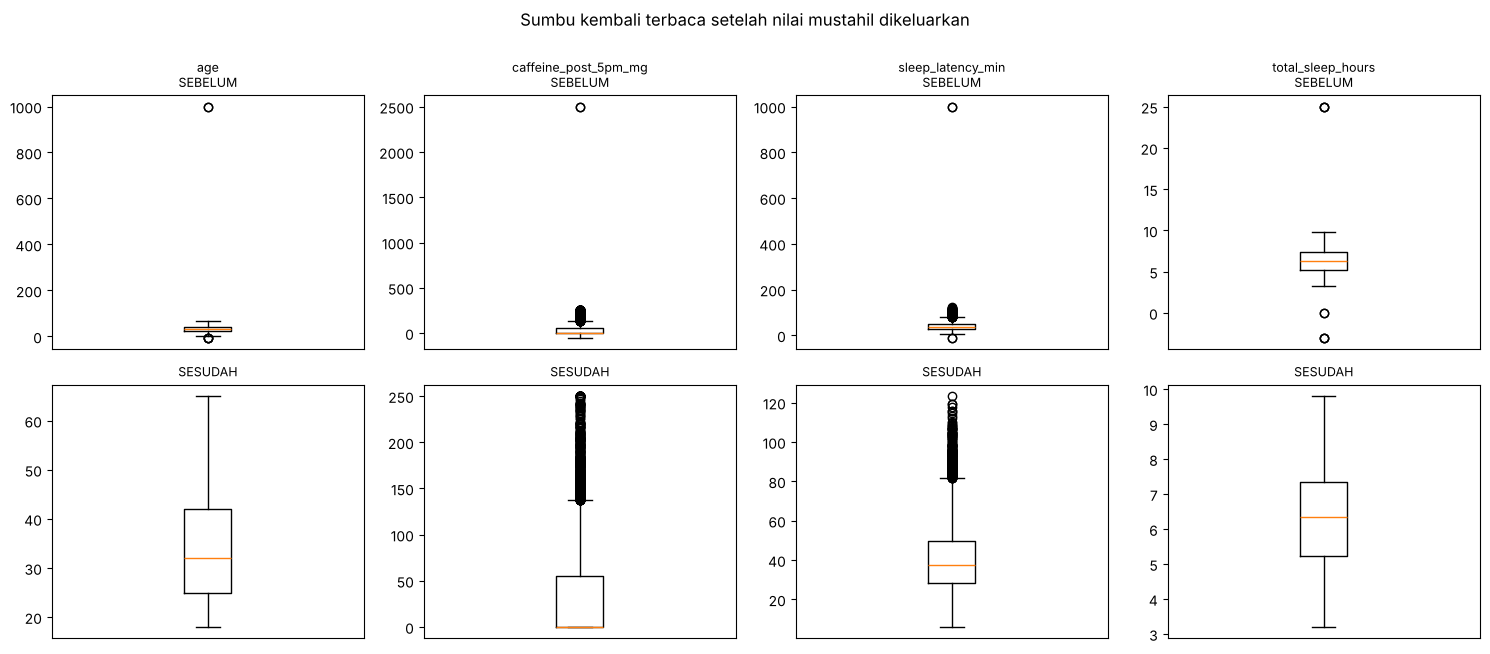

In [24]:
# 8.6 Gambar sebelum-sesudah
fig, ax = plt.subplots(2, 4, figsize=(15, 6.5))
for j, k in enumerate(['age', 'caffeine_post_5pm_mg', 'sleep_latency_min', 'total_sleep_hours']):
    ax[0, j].boxplot(sebelum[k].dropna())
    ax[0, j].set_title(f'{k}\nSEBELUM', fontsize=9)
    ax[1, j].boxplot(sesudah[k].dropna())
    ax[1, j].set_title('SESUDAH', fontsize=9)
    for a in (ax[0, j], ax[1, j]):
        a.set_xticks([])
fig.suptitle('Sumbu kembali terbaca setelah nilai mustahil dikeluarkan', y=1.0)
plt.tight_layout()
plt.savefig(FIG / 'cleaning_sebelum_sesudah.png', dpi=130, bbox_inches='tight')
plt.show()

In [25]:
# 8.7 Proporsi kategori sebelum vs sesudah: pembersihan tidak boleh mengubah komposisi secara tak wajar
def prop(s): return (s.value_counts(normalize=True) * 100).round(1)
print('Proporsi sleep_debt_category (%), sesudah cleaning:'); print(prop(df['sleep_debt_category']).to_string())
print('\nProporsi blue_light_filter_active (%), sesudah cleaning:'); print(prop(df['blue_light_filter_active']).to_string())

Proporsi sleep_debt_category (%), sesudah cleaning:
sleep_debt_category
Moderate Debt        52.5
Mild Deficit         23.6
Optimal Recovery     16.3
Severe Sleep Debt     7.6

Proporsi blue_light_filter_active (%), sesudah cleaning:
blue_light_filter_active
0    53.2
1    46.8


## Langkah 9 — Simpan hasil, verifikasi anonimisasi, dan ekspor `cleaning_log.md`

In [26]:
urutan = ['user_id_hash', 'kelompok_umur', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes',
          'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg',
          'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct',
          'morning_alarm_snoozes', 'next_day_fatigue_score', 'sleep_debt_category']
bersih = df[urutan].copy()
KELUARAN = PROC / 'sleep_data_bersih.csv'
bersih.to_csv(KELUARAN, index=False)

# Verifikasi pada BERKAS yang tersimpan, bukan pada variabel di memori
cek = pd.read_csv(KELUARAN)
print('Tersimpan:', KELUARAN, cek.shape)
assert cek.shape == bersih.shape
assert 'user_id' not in cek.columns and 'age' not in cek.columns
assert not cek.astype(str).apply(lambda c: c.str.contains('USR-')).any().any(), 'ID asli masih terekspos!'
mentah_ids = set(mentah['user_id'].str.strip())
assert not (set(cek['user_id_hash'].astype(str)) & mentah_ids), 'ID asli ada pada hash!'
k_file = cek_k(cek.fillna('(kosong)'), ['kelompok_umur', 'gender', 'occupation_type'])['k']
assert k_file >= 5
print('Anonimisasi terverifikasi pada berkas: tidak ada "USR-", kolom age/user_id tidak ada, k =', int(k_file))

# data/raw tidak berubah selama cleaning
assert hashlib.sha256(RAW.read_bytes()).hexdigest() == SHA_RAW
print('data/raw utuh (SHA-256 sama).')
cek.dtypes.to_frame('dtype').T

Tersimpan: ../data/processed/sleep_data_bersih.csv (8500, 18)


Anonimisasi terverifikasi pada berkas: tidak ada "USR-", kolom age/user_id tidak ada, k = 5
data/raw utuh (SHA-256 sama).


,user_id_hash,kelompok_umur,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
dtype,str,str,str,str,str,float64,str,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,str


In [27]:
# Ekspor jejak keputusan menjadi cleaning_log.md
ringkas = pd.DataFrame(jejak)
tgl = datetime.date.today().isoformat()

baris_md = [
    '# Cleaning Log',
    '',
    f'_Dihasilkan otomatis oleh `notebooks/02_cleaning.ipynb` pada {tgl}. Setiap entri dicatat saat langkahnya dikerjakan._',
    '',
    '## Ringkasan',
    '',
    f'- Data mentah: **{N_MENTAH} baris, {mentah.shape[1]} kolom** (`data/raw/bedtime_screentime_sleep_debt_kotor.csv`, tidak diubah)',
    f'- Data bersih: **{len(bersih)} baris, {bersih.shape[1]} kolom** (`data/processed/sleep_data_bersih.csv`)',
    f'- Baris dibuang: **{N_MENTAH - len(bersih)}** (seluruhnya duplikat persis). Tidak ada baris dibuang karena nilai kosong atau outlier.',
    f'- Jumlah entri keputusan: **{len(ringkas)}**',
    '- SHA-256 `data/raw` (bukti tidak berubah): `' + SHA_RAW + '`',
    '',
    '## Tabel ringkas',
    '',
    '| # | Langkah | Kolom | Baris terdampak | Keputusan | Oleh |',
    '|---|---|---|---|---|---|',
]
for i, r in ringkas.iterrows():
    baris_md.append(f"| {i + 1} | {r['langkah']} | {r['kolom']} | {r['baris_terdampak']} | {r['keputusan']} | {r['oleh']} |")

baris_md += ['', '## Rincian keputusan', '']
for i, r in ringkas.iterrows():
    baris_md += [f"### {i + 1}. {r['langkah']}: {r['kolom']}", '',
                 f"- **Masalah:** {r['masalah']}",
                 f"- **Keputusan:** {r['keputusan']}",
                 f"- **Alasan:** {r['alasan']}",
                 f"- **Alternatif yang dipertimbangkan:** {r['alternatif']}",
                 f"- **Bukti dampak:** {r['bukti']}",
                 f"- **Baris terdampak:** {r['baris_terdampak']}",
                 f"- **Diputuskan oleh:** {r['oleh']}", '']

(ROOT / 'cleaning_log.md').write_text('\n'.join(baris_md), encoding='utf-8')
print('cleaning_log.md ditulis:', len(ringkas), 'entri')
ringkas[['langkah', 'kolom', 'baris_terdampak', 'keputusan']]

cleaning_log.md ditulis: 22 entri


,langkah,kolom,baris_terdampak,keputusan
0,L1 Strip spasi,semua kolom teks,488,"strip() pada seluruh kolom teks, sebelum deduplikasi"
1,L2 Duplikat,seluruh kolom,100,"drop_duplicates(keep=""first"")"
2,L3 Tipe teks -> angka,age,30,"Regex ambil angka, ubah ke float; placeholder tanpa digit menjadi NaN"
3,L3 Tipe teks -> angka,bedtime_phone_minutes,50,"Regex ambil angka, ubah ke float; placeholder tanpa digit menjadi NaN"
4,L3 Tipe teks -> angka,rem_sleep_pct,24,"Regex ambil angka, ubah ke float; placeholder tanpa digit menjadi NaN"
5,L4 Kategori,gender,134,Normalisasi oleh kode; F -> Female dan M -> Male lewat peta manual
6,L4 Kategori,sleep_debt_category,40,"Peta manual eksplisit ke 4 label baku, dilindungi assert"
7,L4 Kategori,"occupation_type, chronotype, primary_bedtime_app",0,"Normalisasi kunci (strip, lowercase, pemisah seragam) lalu petakan ke label ..."
8,L4 Kategori,blue_light_filter_active,0,Petakan ke 1/0 (Int64 agar NaN tetap boleh)
9,L5 Domain,age,8,Ubah menjadi NaN; baris dipertahankan


## Ringkasan pembersihan

- **8.600 → 8.500 baris**: hanya 100 duplikat persis yang dibuang; **tidak ada baris dibuang karena kosong atau outlier**.
- Tipe data diperbaiki, 5 kolom kategorikal + 1 biner diseragamkan (dua keputusan manual dicatat eksplisit).
- Nilai mustahil diubah menjadi `NaN`, **bukan** dikarang atau dipotong.
- **Nilai kosong tidak diimputasi** pada kolom numerik; keputusan didukung eksperimen (efek kecil tetapi searah: variasi menyusut, hubungan sedikit bergeser) dan biaya `dropna()` total (~14% baris).
- Data pribadi: `user_id` di-HMAC, `age` digeneralisasi, k-anonymity ≥ 5 terverifikasi pada berkas yang tersimpan.
- Diagnosis diulang pada data bersih: 0 pelanggaran domain, 0 ketidakcocokan antarkolom.

**Untuk analisis lanjut (M3):** lapor *n* **setelah** `dropna()` per analisis, dan sebutkan bahwa `sleep_latency_min` dan `deep_sleep_pct` mungkin MNAR (tidak terbukti, tidak terbantahkan).